In [ ]:
import os
import glob
import ast
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import torch
from libpysal.weights import KNN
from esda.moran import Moran
from scipy.optimize import minimize

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = "cpu"
print(f"Using device: {device}")

In [ ]:
# --- Circular Statistics Helpers ---

def circular_mean(angles):
    return np.arctan2(np.sum(np.sin(angles)), np.sum(np.cos(angles)))

def circular_correlation(alpha, beta):
    mu_alpha = circular_mean(alpha)
    mu_beta = circular_mean(beta)
    numerator = np.sum(np.sin(alpha - mu_alpha) * np.sin(beta - mu_beta))
    denominator = np.sqrt(
        np.sum(np.sin(alpha - mu_alpha) ** 2) * np.sum(np.sin(beta - mu_beta) ** 2)
    )
    return numerator / denominator if denominator != 0 else 0.0

def mean_resultant_length(phi, theta):
    delta = theta - phi
    C = np.mean(np.cos(delta))
    S = np.mean(np.sin(delta))
    return np.sqrt(C**2 + S**2)

def neg_abs_circ_corr(center, points, labels):
    dx = points[:, 0] - center[0]
    dy = points[:, 1] - center[1]
    if np.any((np.abs(dx) < 1e-12) & (np.abs(dy) < 1e-12)):
        return 0.0
    phi = np.arctan2(dy, dx)
    corr = circular_correlation(phi, labels)
    if np.isnan(corr):
        return 0.0
    return -abs(corr)

def find_optimal_center(points, labels, init_guesses=None, method="Nelder-Mead"):
    if init_guesses is None:
        mean_c = np.mean(points, axis=0)
        bbox_c = (np.min(points, axis=0) + np.max(points, axis=0)) / 2.0
        init_guesses = [mean_c, bbox_c]
    best_center = None
    best_corr = -1.0
    best_mrl = 0.0
    for guess in init_guesses:
        result = minimize(
            neg_abs_circ_corr,
            guess,
            args=(points, labels),
            method=method,
            options={"xatol": 1e-7, "fatol": 1e-7, "maxiter": 500},
        )
        corr = -result.fun
        if corr > best_corr:
            best_corr = corr
            best_center = result.x
    phi_opt = np.arctan2(points[:, 1] - best_center[1], points[:, 0] - best_center[0])
    best_mrl = mean_resultant_length(phi_opt, labels)
    return best_center, best_corr, best_mrl


In [ ]:
def analyze_spatial_autocorrelation(
    var_title,
    geom_csv_path,
    meta_idx,
    latents_path,
    iteration,
    device="cpu",
    circular=False,
    time=False,
):
    """
    Analyze spatial autocorrelation.

    Always produces a Moran's I scatter plot (no centers).
    For circular variables (T, Long), additionally produces a separate
    circular-correlation plot with the optimal / mean / bbox centers.

    The geometry CSV may contain multiple rows (one per iteration).
    Row selection follows the original convention: iteration // 2 - 1.
    If the file has only one row, that row is used for all iterations.
    """
    # ---------- Load Geometry ----------
    df_geom = pd.read_csv(geom_csv_path)
    for col in ["rotation_matrix", "translation_vec", "lambda_vec"]:
        df_geom[col] = df_geom[col].apply(ast.literal_eval)

    # Select the correct row for this iteration
    if len(df_geom) == 1:
        geom_row = df_geom.iloc[0]
    else:
        row_idx = iteration // 2 - 1
        if row_idx >= len(df_geom):
            raise ValueError(
                f"Geometry file {geom_csv_path} has {len(df_geom)} rows, "
                f"but iteration {iteration} requires row index {row_idx}."
            )
        geom_row = df_geom.iloc[row_idx]

    R_m = torch.tensor(geom_row["rotation_matrix"], device=device, dtype=torch.float32)
    t_m = torch.tensor(geom_row["translation_vec"], device=device, dtype=torch.float32)
    l_m = torch.tensor(geom_row["lambda_vec"], device=device, dtype=torch.float32)

    # ---------- Load Latents ----------
    data = torch.load(latents_path, map_location=device)

    if time:
        current_meta = data["meta"]
        lats = current_meta[:, 0]
        alts = current_meta[:, 3]
        mask = (lats > 15) & (lats < 66) & (alts < 4000)
        X = data["latents"][mask]
        labels = current_meta[:, -1][mask].cpu().numpy().flatten()
    else:
        X = data["latents"]
        labels = data["meta"][:, meta_idx].cpu().numpy().flatten()
        if circular:
            labels = labels * np.pi / 180

    # ---------- Apply Transformation ----------
    with torch.no_grad():
        X_centered_m = X.to(device) + t_m
        X_rotated_m = torch.matmul(X_centered_m, R_m)
        top_2_m = torch.argsort(l_m.abs(), descending=True)[:2]
        Ls_model = X_rotated_m[:, top_2_m].cpu().numpy()

    # ---------- Moran's I ----------
    gdf_m = gpd.GeoDataFrame(
        {"label": labels},
        geometry=gpd.points_from_xy(Ls_model[:, 0], Ls_model[:, 1]),
    )
    w_m = KNN.from_dataframe(gdf_m, k=8)
    w_m.transform = "R"
    mi = Moran(gdf_m["label"], w_m)

    # ============================================================
    # FIGURE 1 — Moran's I (always produced, NEVER shows centers)
    # ============================================================
    cmap_moran = "twilight" if circular else "viridis"

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(
        Ls_model[:, 0], Ls_model[:, 1],
        c=labels, cmap=cmap_moran, s=5, alpha=0.5,
    )
    plt.colorbar(scatter, label=var_title)
    plt.title(f"{var_title} — Moran's I = {mi.I:.4f} (p = {mi.p_sim:.4f})")
    plt.xlabel("Latent Dim 1")
    plt.ylabel("Latent Dim 2")
    plt.grid(True, alpha=0.2)
    plt.tight_layout()
    png_path = f"very_low_or_high_corr/moran_{var_title.replace(' ', '_')}_iter{iteration}.png"
    plt.savefig(png_path, format="png", dpi=300)
    plt.show()

    print(f"\n--- {var_title} (iter {iteration}) ---")
    print(f"Moran's I:        {mi.I:.6f}")
    print(f"Moran's I p-val:  {mi.p_sim:.6f}")
    print(f"Moran's I z-score:{mi.z_sim:.6f}")

    # ============================================================
    # FIGURE 2 — Circular Correlation (only for circular variables)
    # ============================================================
    if circular:
        center_m_opt, corr_m_opt, mrl_m_opt = find_optimal_center(Ls_model, labels)
        center_m_mean = np.mean(Ls_model, axis=0)
        center_m_bbox = (np.min(Ls_model, axis=0) + np.max(Ls_model, axis=0)) / 2.0

        plt.figure(figsize=(8, 6))
        scatter2 = plt.scatter(
            Ls_model[:, 0], Ls_model[:, 1],
            c=labels, cmap="twilight", s=5, alpha=0.5,
        )
        plt.colorbar(scatter2, label=var_title)

        plt.scatter(
            center_m_opt[0], center_m_opt[1],
            color="lime", marker="*", s=250, edgecolor="black",
            label=f"Center (r={round(corr_m_opt, 2)}, R={round(mrl_m_opt, 2)})",
            zorder=4,
        )
        # plt.scatter(
        #     center_m_mean[0], center_m_mean[1],
        #     color="red", marker="X", s=150, edgecolor="black",
        #     label="Mean Center", zorder=3,
        # )
        # plt.scatter(
        #     center_m_bbox[0], center_m_bbox[1],
        #     color="cyan", marker="o", s=100,
        #     facecolors="none", edgecolors="cyan", linewidths=2,
        #     label="BBox Center", zorder=2,
        # )
        plt.legend(loc="best")
        plt.title(f"{var_title} — Circular Correlation (r={corr_m_opt:.4f}, R={mrl_m_opt:.4f})")
        plt.xlabel("Latent Dim 1")
        plt.ylabel("Latent Dim 2")
        plt.grid(True, alpha=0.2)
        plt.tight_layout()
        png_path = f"very_low_or_high_corr/circular_corr_{var_title.replace(' ', '_')}_iter{iteration}.png"
        plt.savefig(png_path, format="png", dpi=300)
        plt.show()

        print(f"Circular Corr:    {corr_m_opt:.6f}")
        print(f"Mean Res. Length: {mrl_m_opt:.6f}")

    return mi.I, mi.p_sim, mi.z_sim


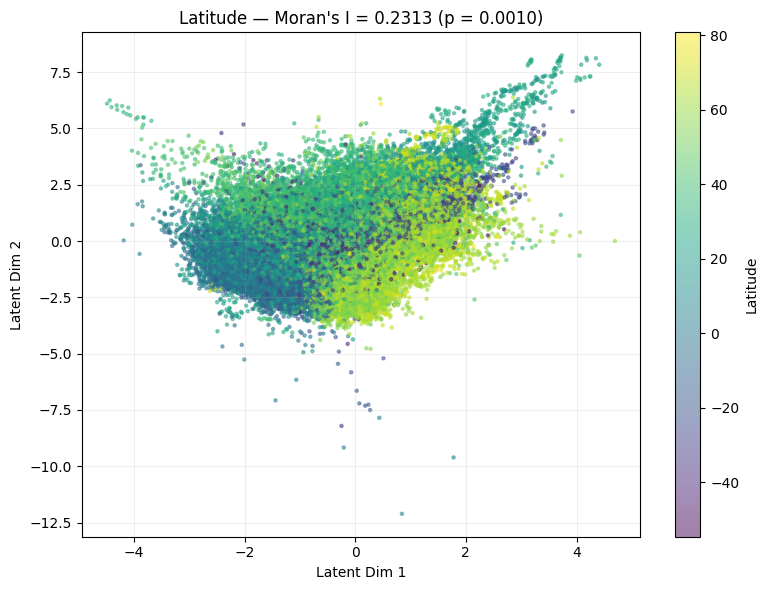

In [ ]:
# ============================================================
# CONFIGURATION
# ============================================================
# TARGET_ITERATIONS = [0,2,4,6,8,10,12]
TARGET_ITERATIONS = [12]
METRIC = "moran_I"          # or "circ_corr", "moran_I"
ORDER = "lowest"           # or "lowest" or highest
RANK = 1                    # 1 = lowest/highest, 2 = 2nd, etc.

RESULTS_DIR = "../results"
TRANSFORMATIONS_DIR = "../transformations"
DATA_DIR = "../data"

VARIABLES = {
    "H":   {"title": "Altitude",   "meta_idx":  3, "circular": False, "time": False},
    "L":   {"title": "Latitude",   "meta_idx":  0, "circular": False, "time": False},
    "Long":{"title": "Longitude",  "meta_idx":  1, "circular": True,  "time": False},
    "T":   {"title": "Season",     "meta_idx": -1, "circular": True,  "time": True },
}

def find_transformation_file(transformations_dir, seed):
    direct = os.path.join(transformations_dir, f"{seed}.csv")
    if os.path.exists(direct):
        return direct
    pattern = os.path.join(transformations_dir, f"{seed}_geometry_results*.csv")
    matches = glob.glob(pattern)
    if matches:
        return matches[0]
    pattern = os.path.join(transformations_dir, f"*{seed}*.csv")
    matches = glob.glob(pattern)
    if matches:
        return matches[0]
    return None

for var_code, var_config in VARIABLES.items():
    results_file = os.path.join(RESULTS_DIR, f"{var_code}_results.csv")
    if not os.path.exists(results_file):
        print(f"\n⚠️  Results file not found: {results_file}")
        continue

    df = pd.read_csv(results_file)
    df_filtered = df[df["iteration"].isin(TARGET_ITERATIONS)]
    if df_filtered.empty:
        print(f"\n⚠️  No data for {var_code} with iterations {TARGET_ITERATIONS}")
        continue

    if METRIC not in df_filtered.columns:
        print(f"\n⚠️  Metric '{METRIC}' not found in {var_code}_results.csv. Skipping.")
        continue

    ascending = (ORDER == "lowest")
    df_sorted = df_filtered.sort_values(by=METRIC, ascending=ascending)
    if len(df_sorted) < RANK:
        print(f"\n⚠️  Not enough results for {var_code} (found {len(df_sorted)}, need {RANK})")
        continue

    selected = df_sorted.iloc[RANK - 1]
    seed = selected["seed"]
    iteration = int(selected["iteration"])

    print("\n" + "=" * 70)
    print(f"  {var_config['title']} — {RANK}{'th' if RANK > 3 else {1:'st',2:'nd',3:'rd'}.get(RANK,'th')} {ORDER} {METRIC}")
    print("=" * 70)
    print(f"  Seed:      {seed}")
    print(f"  Iteration: {iteration}")
    print(f"  {METRIC}:  {selected[METRIC]:.6f}")
    print("=" * 70)

    trans_file = find_transformation_file(TRANSFORMATIONS_DIR, seed)
    if trans_file is None:
        print(f"  ❌ Transformation file not found for seed: {seed}")
        continue
    print(f"  📁 Transformation file: {trans_file}")

    latents_path = os.path.join(DATA_DIR, f"latents_{iteration}_92160_for_intervention.pt")
    if not os.path.exists(latents_path):
        print(f"  ❌ Latents file not found: {latents_path}")
        continue
    print(f"  📁 Latents file:        {latents_path}")

    analyze_spatial_autocorrelation(
        var_title=var_config["title"],
        geom_csv_path=trans_file,
        meta_idx=var_config["meta_idx"],
        latents_path=latents_path,
        iteration=iteration,
        device=device,
        circular=var_config["circular"],
        time=var_config["time"],
    )


In [ ]:
# TODO change name from season to time
# 2. remove captions for Mean center and bbox center, leave only caption for Optimal center and call it just center
# 3. save pictures as pdf so i can include it in a report
# 4. make colorbar consistent across all plots